Import all the libraries

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    r2_score ,
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix)

import tensorflow as tf



In [87]:
RANDOM_STATE=24
tf.random.set_seed(seed=RANDOM_STATE)

EPOCHES=1000
ALPHA= 0.0001  # Learning Rate
N_SAMPLE= 1000
TEST_SIZE=0.2


# Initialize the generator (optionally pass a seed for reproducibility)
rng = np.random.default_rng(seed=RANDOM_STATE)
param = {
    'legend.fontsize': 'medium',
    'figure.figsize' : (15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium',

}

plt.rcParams.update(param)

CMAP  = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

Helper Function

In [88]:
physical_devices = tf.config.list_physical_devices('GPU')
print("Num GPUs Available: ", len(physical_devices))
physical_devices

if len(physical_devices) > 0:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)

Num GPUs Available:  1


## 3. Read Wine Data set

In [89]:
data_df = pd.read_csv('/content/drive/MyDrive/Datasets for DL/wine.csv', header=None)


data_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [90]:
data_df.shape

(178, 14)

In [91]:
data_df.describe().T



,count,mean,std,min,25%,50%,75%,max
0,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
1,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
2,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
3,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
4,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
5,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
6,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
7,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
8,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
9,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [92]:
data_df.describe().T

,count,mean,std,min,25%,50%,75%,max
0,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
1,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
2,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
3,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
4,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
5,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
6,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
7,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
8,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
9,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [93]:
data_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       178 non-null    float64
 1   1       178 non-null    float64
 2   2       178 non-null    float64
 3   3       178 non-null    float64
 4   4       178 non-null    int64  
 5   5       178 non-null    float64
 6   6       178 non-null    float64
 7   7       178 non-null    float64
 8   8       178 non-null    float64
 9   9       178 non-null    float64
 10  10      178 non-null    float64
 11  11      178 non-null    float64
 12  12      178 non-null    int64  
 13  13      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [94]:

for col in data_df.columns:
    print(f'{col},{data_df[col].unique()}')

0,[14.23 13.2  13.16 14.37 13.24 14.2  14.39 14.06 14.83 13.86 14.1  14.12
 13.75 14.75 14.38 13.63 14.3  13.83 14.19 13.64 12.93 13.71 12.85 13.5
 13.05 13.39 13.3  13.87 14.02 13.73 13.58 13.68 13.76 13.51 13.48 13.28
 13.07 14.22 13.56 13.41 13.88 14.21 13.9  13.94 13.82 13.77 13.74 13.29
 13.72 12.37 12.33 12.64 13.67 12.17 13.11 13.34 12.21 12.29 13.49 12.99
 11.96 11.66 13.03 11.84 12.7  12.   12.72 12.08 12.67 12.16 11.65 11.64
 12.69 11.62 12.47 11.81 12.6  12.34 11.82 12.51 12.42 12.25 12.22 11.61
 11.46 12.52 11.76 11.41 11.03 12.77 11.45 11.56 11.87 12.07 12.43 11.79
 12.04 12.86 12.88 12.81 12.53 12.84 13.36 13.52 13.62 12.87 13.32 13.08
 12.79 13.23 12.58 13.17 13.84 12.45 14.34 12.36 13.69 12.96 13.78 13.45
 12.82 13.4  12.2  14.16 13.27 14.13]
1,[1.71 1.78 2.36 1.95 2.59 1.76 1.87 2.15 1.64 1.35 2.16 1.48 1.73 1.81
 1.92 1.57 1.59 3.1  1.63 3.8  1.86 1.6  2.05 1.77 1.72 1.9  1.68 1.5
 1.66 1.83 1.53 1.8  1.65 3.99 3.84 1.89 3.98 4.04 3.59 2.02 1.75 1.67
 1.7  1.97 1.43 0

In [95]:
data_df.isna().sum()

,0
0,0
1,0
2,0
3,0
4,0
5,0
6,0
7,0
8,0
9,0


<Axes: >

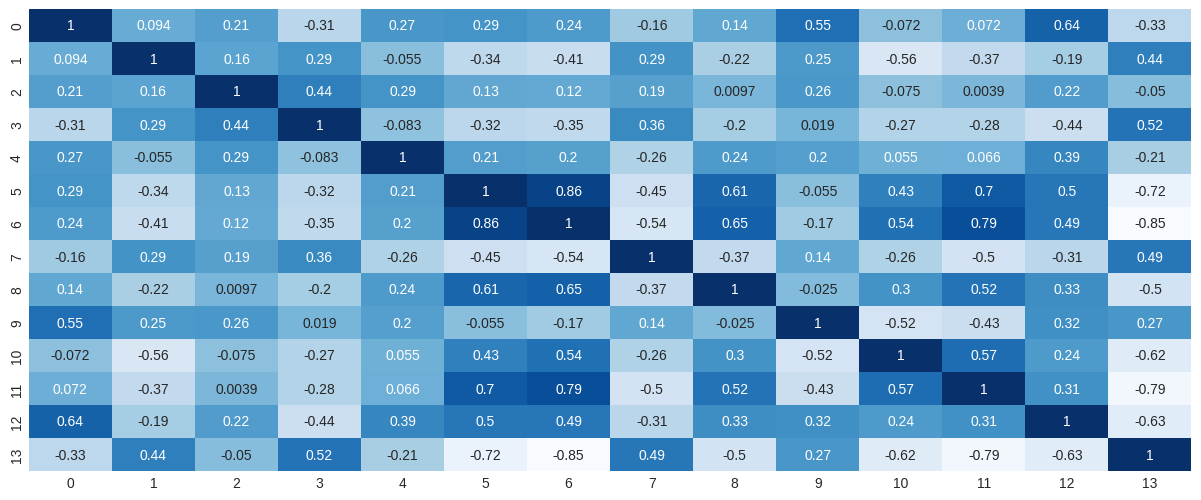

In [96]:
fig , ax = plt.subplots(figsize=(15,6))

sns.heatmap(
            data = data_df.corr(),
            ax=ax,
            annot=True,
            cmap='Blues',

            fmt = '.2g',
            cbar = False)

In [97]:
labels = data_df[data_df.columns[-1]]
features_df = data_df.drop(data_df.columns[-1],axis = 1)
# display(features_df) , display(labels)
features_df.shape , labels.shape

((178, 13), (178,))

In [98]:
X_train, X_test, y_train, y_test = train_test_split(features_df, labels,
                                                    test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE,
                                                    stratify = labels)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(142, 13) (36, 13) (142,) (36,)


In [99]:
# Fit transform Train / and only Transform Test
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(142, 13) (36, 13) (142,) (36,)


# **Prepare Model**

In [100]:
# tf.keras.layers.Dense?  # To view documentation for any library

In [101]:
model = tf.keras.Sequential(
    [
      tf.keras.Input(shape=(X_train.shape[1],)),  # Input layer specifying the input shape    no of columns we pass
      tf.keras.layers.Dense(8, activation='relu'), # Hidden layer
      tf.keras.layers.Dense(3) # Output layer   no of classes we pass
    ]
    )

In [102]:
 # we can choose numbers based on funnel like structure or exponential
 # we are going to use logits so no need to pass activation in last
 # sparse representation of target  stores index in cloumns for ohe where 1 is available.
#  import sys
# sys.float_info.min , sys.float_info.max


In [103]:

prediction = model(X_train[:1])
prediction

<tf.Tensor: shape=(1, 3), dtype=float32, numpy=array([[ 0.25112987,  0.96096104, -3.1081839 ]], dtype=float32)>

In [104]:
tf.nn.softmax(prediction).numpy().sum() # check whether math is correct

np.float32(0.99999994)

In [105]:

model.summary()
# 13 * 8 + 8
# 8 * 3 + 3

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 8)              │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139 (556.00 B)

 Trainable params: 139 (556.00 B)

 Non-trainable params: 0 (0.00 B)

In [106]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits = True)
# why we dont use activation layer in last layer ? in detail

In [107]:
optimizer = tf.keras.optimizers.Adam(learning_rate = ALPHA)
model.compile(optimizer=optimizer ,
              loss = loss_fn,
              metrics = ['accuracy'])

In [ ]:
history = model.fit(X_train, y_train,
                    validation_data = [X_test, y_test] ,
                    epochs = EPOCHES)

Epoch 1/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 349ms/step - accuracy: 0.2113 - loss: 1.1750 - val_accuracy: 0.1667 - val_loss: 1.1407
Epoch 2/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.2113 - loss: 1.1713 - val_accuracy: 0.1667 - val_loss: 1.1368
Epoch 3/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2113 - loss: 1.1676 - val_accuracy: 0.1667 - val_loss: 1.1329
Epoch 4/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2113 - loss: 1.1639 - val_accuracy: 0.1667 - val_loss: 1.1290
Epoch 5/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.2113 - loss: 1.1603 - val_accuracy: 0.1667 - val_loss: 1.1252
Epoch 6/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2113 - loss: 1.1567 - val_accuracy: 0.1667 - val_loss: 1.1214
Epoch 7/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.2113 - loss: 1.1530 - val_accuracy: 0.1667 - val_loss: 1.1175
Epoch 8/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2183 - loss: 1.1494 - val_accuracy: 0.1667 - 